# Exploration of Water Quality Station (WQS) Datasets

In [3]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

WQP_DIR = ROOT / "data" / "raw" / "wqp"
STATION_DIR = WQP_DIR / "stations"
MANIFEST_PATH = WQP_DIR / "station_manifest.csv"

station_files = sorted(STATION_DIR.glob("*.csv"))

print(f"Project root: {ROOT}")
print(f"Station files found: {len(station_files)}")
print(f"Manifest exists: {MANIFEST_PATH.exists()}")

for f in station_files:
    print(f"  {f.name}")

Project root: /courses/DS5500.202710/teams/team4
Station files found: 10
Manifest exists: True
  03130003.csv
  03150106.csv
  03150202.csv
  03160111.csv
  19010210.csv
  19010301.csv
  19020401.csv
  19020503.csv
  19020701.csv
  19080309.csv


In [4]:
manifest = pd.read_csv(MANIFEST_PATH)
display(manifest)
print("\nColumns:", manifest.columns.tolist())

,huc8,status,path,error
0,19020701,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
1,19020503,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
2,19010301,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
3,19010210,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
4,19080309,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
5,19020401,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
6,3150202,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
7,3130003,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
8,3150106,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN
9,3160111,downloaded,/courses/DS5500.202710/teams/team4/data/raw/wq...,NaN



Columns: ['huc8', 'status', 'path', 'error']


## Load and combine files

In [5]:
frames = []

for f in station_files:
    df = pd.read_csv(f, low_memory=False)
    df["source_huc8"] = f.stem
    frames.append(df)

if not frames:
    raise ValueError(f"No station CSVs found in {STATION_DIR}")

stations = pd.concat(frames, ignore_index=True)

print(f"Combined rows: {len(stations):,}")
print(f"Columns: {len(stations.columns)}")
display(stations.head())

Combined rows: 15,625
Columns: 38


,OrganizationIdentifier,OrganizationFormalName,MonitoringLocationIdentifier,MonitoringLocationName,MonitoringLocationTypeName,MonitoringLocationDescriptionText,HUCEightDigitCode,DrainageAreaMeasure/MeasureValue,DrainageAreaMeasure/MeasureUnitCode,ContributingDrainageAreaMeasure/MeasureValue,...,LocalAqfrName,FormationTypeText,AquiferTypeName,ConstructionDateText,WellDepthMeasure/MeasureValue,WellDepthMeasure/MeasureUnitCode,WellHoleDepthMeasure/MeasureValue,WellHoleDepthMeasure/MeasureUnitCode,ProviderName,source_huc8
0,USGS-AL,USGS Alabama Water Science Center,USGS-02341480,MILL CREEK NEAR PHENIX CITY AL,Stream,NaN,3130003,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NWIS,03130003
1,USGS-AL,USGS Alabama Water Science Center,USGS-02342115,"UCHEE CREEK NEAR HUGLEY, AL.",Stream,NaN,3130003,94.6,sq mi,94.6,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NWIS,03130003
2,USGS-AL,USGS Alabama Water Science Center,USGS-02342125,"UCHEE CREEK NR CRAWFORD, ALA",Stream,NaN,3130003,134.0,sq mi,134.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NWIS,03130003
3,USGS-AL,USGS Alabama Water Science Center,USGS-02342150,UCHEE CREEK NEAR SEALE AL,Stream,NaN,3130003,134.0,sq mi,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NWIS,03130003
4,USGS-AL,USGS Alabama Water Science Center,USGS-02342180,"UCHEE CREEK NEAR SEALE, AL.",Stream,NaN,3130003,162.0,sq mi,162.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NWIS,03130003


Notice how HUCEightDigitCode is 7 digits sometimes - we need to normalize those 7 digit codes by front-padding them with 0s

In [18]:
# Normalize HUC8 codes to 8-character strings
stations["HUCEightDigitCode"] = (
    stations["HUCEightDigitCode"]
    .astype("Int64")
    .astype("string")
    .str.zfill(8)
)

stations["source_huc8"] = (
    stations["source_huc8"]
    .astype("string")
    .str.zfill(8)
)

In [6]:
# Column names and data types
schema = pd.DataFrame({
    "dtype": stations.dtypes.astype(str),
    "non_null": stations.notna().sum(),
    "null_pct": (stations.isna().mean() * 100).round(1),
    "unique_values": stations.nunique(dropna=True)
}).sort_values("null_pct", ascending=False)

display(schema)

,dtype,non_null,null_pct,unique_values
LocalAqfrName,float64,0,100.0,0
ContributingDrainageAreaMeasure/MeasureValue,float64,408,97.4,374
ContributingDrainageAreaMeasure/MeasureUnitCode,object,408,97.4,2
DrainageAreaMeasure/MeasureUnitCode,str,786,95.0,2
DrainageAreaMeasure/MeasureValue,float64,786,95.0,652
AquiferTypeName,object,853,94.5,4
AquiferName,object,952,93.9,7
MonitoringLocationDescriptionText,object,1245,92.0,954
FormationTypeText,object,2271,85.5,60
ConstructionDateText,object,10533,32.6,5131


In [7]:
# Check for duplicate stations
id_col = "MonitoringLocationIdentifier"

if id_col in stations.columns:
    print("Unique station IDs:", stations[id_col].nunique())
    print("Rows with duplicated station IDs:",
          stations[id_col].duplicated(keep=False).sum())
    display(
        stations[stations[id_col].duplicated(keep=False)]
        .sort_values(id_col)
        .head(20)
    )
else:
    print(f"{id_col} not found. Check the schema for the station ID column.")

Unique station IDs: 15625
Rows with duplicated station IDs: 0


,OrganizationIdentifier,OrganizationFormalName,MonitoringLocationIdentifier,MonitoringLocationName,MonitoringLocationTypeName,MonitoringLocationDescriptionText,HUCEightDigitCode,DrainageAreaMeasure/MeasureValue,DrainageAreaMeasure/MeasureUnitCode,ContributingDrainageAreaMeasure/MeasureValue,...,LocalAqfrName,FormationTypeText,AquiferTypeName,ConstructionDateText,WellDepthMeasure/MeasureValue,WellDepthMeasure/MeasureUnitCode,WellHoleDepthMeasure/MeasureValue,WellHoleDepthMeasure/MeasureUnitCode,ProviderName,source_huc8


In [9]:
# Show WQS types, states, and HUCs
for col in [
    "MonitoringLocationTypeName",
    "StateCode",
    "HUCEightDigitCode"
]:
    if col in stations.columns:
        print(f"\n--- {col} ---")
        display(stations[col].value_counts(dropna=False).head(15).to_frame("count"))


--- MonitoringLocationTypeName ---


,count
MonitoringLocationTypeName,
Well,11542
River/Stream,1374
Stream,1127
River/Stream Perennial,352
Spring,212
"Lake, Reservoir, Impoundment",174
Facility: Water-distribution system,170
Lake,154
Atmosphere,150



--- StateCode ---


,count
StateCode,
2,11641
1,3574
13,410



--- HUCEightDigitCode ---


,count
HUCEightDigitCode,
19020401,10069
3150106,1193
3150202,1135
3130003,952
19010301,802
3160111,704
19020701,407
19080309,283
19010210,77


We only want stream, river/stream, and spring stations. Apply filter below:

In [25]:
surface_water_types = [
    "Stream",
    "River/Stream"#,
    #"Spring",
]

surface_stations = stations[
    stations["MonitoringLocationTypeName"].isin(surface_water_types)
].copy()

print("Candidate surface-water locations:", len(surface_stations))
print(
    surface_stations["MonitoringLocationTypeName"]
    .value_counts()
)

Candidate surface-water locations: 2501
MonitoringLocationTypeName
River/Stream    1374
Stream          1127
Name: count, dtype: int64


,rows,unique_stations
source_huc8,,
03150202,482,482
03150106,427,427
19020401,391,391
03160111,381,381
03130003,329,329
19010301,248,248
19020701,125,125
19080309,63,63
19010210,54,54


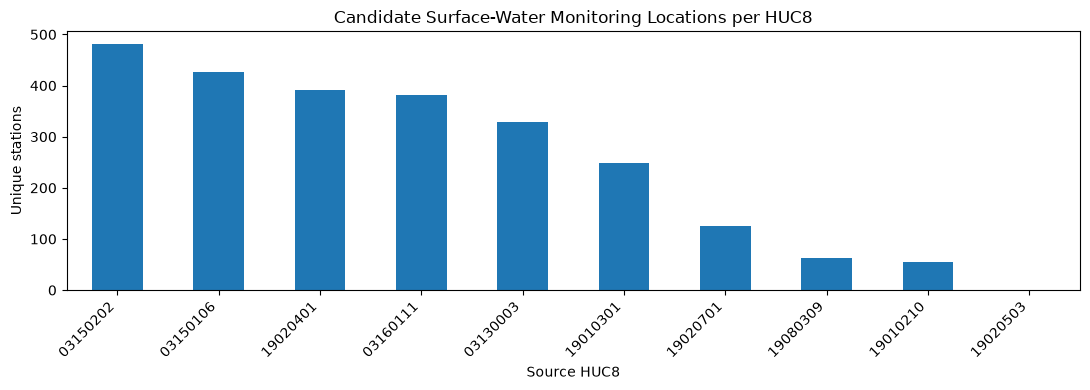

In [26]:
# Compare surface-water station counts across HUC8s
station_counts = (
    surface_stations.groupby("source_huc8")
    .agg(
        rows=("source_huc8", "size"),
        unique_stations=("MonitoringLocationIdentifier", "nunique")
    )
    .sort_values("unique_stations", ascending=False)
)

display(station_counts)

station_counts["unique_stations"].plot(
    kind="bar",
    figsize=(11, 4),
    title="Candidate Surface-Water Monitoring Locations per HUC8"
)
plt.xlabel("Source HUC8")
plt.ylabel("Unique stations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Map WQS with HUC 8s

In [27]:
import folium
import geopandas as gpd
from folium.plugins import MarkerCluster

gpkg_path = "../data/raw/wbd/WBD_National_GPKG.gpkg"
wbd_df = gpd.read_file(gpkg_path,layer="WBDHU8")

In [28]:
import folium
import pandas as pd
import geopandas as gpd
from folium.plugins import MarkerCluster

# HUC8s corresponding to the filtered surface-water stations
huc8_codes = (
    surface_stations["source_huc8"]
    .dropna()
    .astype(str)
    .str.zfill(8)
    .unique()
)

# Ensure WBD HUC8 codes are strings
wbd_df["huc8"] = wbd_df["huc8"].astype(str).str.zfill(8)

# Filter to HUC8s represented in the candidate station data
watersheds = (
    wbd_df[wbd_df["huc8"].isin(huc8_codes)]
    .to_crs("EPSG:4326")
    .copy()
)

print(f"HUC8 codes in surface-water station data: {len(huc8_codes)}")
print(f"Matching WBD watershed polygons: {len(watersheds)}")

HUC8 codes in surface-water station data: 10
Matching WBD watershed polygons: 10


In [29]:
stations_map = surface_stations.copy()

stations_map["LatitudeMeasure"] = pd.to_numeric(
    stations_map["LatitudeMeasure"], errors="coerce"
)
stations_map["LongitudeMeasure"] = pd.to_numeric(
    stations_map["LongitudeMeasure"], errors="coerce"
)

stations_map = stations_map[
    stations_map["LatitudeMeasure"].between(-90, 90)
    & stations_map["LongitudeMeasure"].between(-180, 180)
].copy()

# Avoid plotting duplicate locations for the same station
stations_map = stations_map.drop_duplicates(
    subset="MonitoringLocationIdentifier"
)

print(f"Candidate surface-water stations: {len(surface_stations):,}")
print(f"Candidate stations with valid coordinates: {len(stations_map):,}")

Candidate surface-water stations: 2,501
Candidate stations with valid coordinates: 2,501


In [30]:
# Center on the selected watersheds
minx, miny, maxx, maxy = watersheds.total_bounds
center = [(miny + maxy) / 2, (minx + maxx) / 2]

m = folium.Map(
    location=center,
    zoom_start=6,
    tiles="OpenStreetMap"
)

# Simplify polygons for faster rendering
watersheds["geometry"] = watersheds.geometry.simplify(
    tolerance=0.001,
    preserve_topology=True
)

# Watershed boundaries
folium.GeoJson(
    watersheds[["huc8", "name", "geometry"]].to_json(),
    name="HUC8 Watersheds",
    style_function=lambda feature: {
        "color": "#2463a6",
        "weight": 2,
        "fillColor": "#6baed6",
        "fillOpacity": 0.15
    },
    tooltip=folium.GeoJsonTooltip(
        fields=["huc8", "name"],
        aliases=["HUC8:", "Watershed:"]
    )
).add_to(m)

# Monitoring stations
station_cluster = MarkerCluster(
    name="WQP Monitoring Stations"
).add_to(m)

for _, row in stations_map.iterrows():
    folium.CircleMarker(
        location=[
            row["LatitudeMeasure"],
            row["LongitudeMeasure"]
        ],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.8,
        tooltip=str(row.get("MonitoringLocationIdentifier", "Unknown station")),
        popup=(
            f"<b>Station:</b> {row.get('MonitoringLocationName', 'Unknown')}<br>"
            f"<b>ID:</b> {row.get('MonitoringLocationIdentifier', 'Unknown')}<br>"
            f"<b>Source HUC8:</b> {row.get('source_huc8', 'Unknown')}"
        )
    ).add_to(station_cluster)

folium.LayerControl().add_to(m)

# Zoom to include all selected HUC8 polygons
m.fit_bounds([[miny, minx], [maxy, maxx]])

m

# Now create csv of sample stations to use for WQP result pilot

In [31]:
from pathlib import Path
import pandas as pd

# Start with candidate surface-water stations that have valid coordinates.
pilot_candidates = surface_stations.copy()

pilot_candidates["LatitudeMeasure"] = pd.to_numeric(
    pilot_candidates["LatitudeMeasure"], errors="coerce"
)
pilot_candidates["LongitudeMeasure"] = pd.to_numeric(
    pilot_candidates["LongitudeMeasure"], errors="coerce"
)

pilot_candidates = pilot_candidates[
    pilot_candidates["LatitudeMeasure"].between(-90, 90)
    & pilot_candidates["LongitudeMeasure"].between(-180, 180)
].drop_duplicates("MonitoringLocationIdentifier")

# Sample up to five stations per HUC8 for a small initial test.
pilot_parts = []
for huc8, group in pilot_candidates.groupby("source_huc8"):
    pilot_parts.append(
        group.sample(n=min(5, len(group)), random_state=42)
    )

pilot_stations = pd.concat(pilot_parts, ignore_index=True)

print(f"Selected {len(pilot_stations)} pilot stations")
display(
    pilot_stations.groupby("source_huc8")
    .size()
    .rename("pilot_stations")
    .to_frame()
)

# Save the input CSV used by the Slurm-run downloader.
results_dir = Path("../data/raw/wqp/results")
results_dir.mkdir(parents=True, exist_ok=True)

output_file = results_dir / "pilot_station_selection.csv"
pilot_stations.to_csv(output_file, index=False)

print(f"Saved station selection to: {output_file.resolve()}")

Selected 46 pilot stations


,pilot_stations
source_huc8,
03130003,5
03150106,5
03150202,5
03160111,5
19010210,5
19010301,5
19020401,5
19020503,1
19020701,5


Saved station selection to: /courses/DS5500.202710/teams/team4/data/raw/wqp/results/pilot_station_selection.csv
